# Grafos con [GraphFrames](https://graphframes.io/)

Cuando lo importante de los datos son las **relaciones** (quién sigue a quién, quién le escribe a quién), conviene modelarlos como un grafo.

- **Vértices**: las entidades (personas, cuentas, canales).
- **Aristas**: las relaciones entre ellas.

Spark trae GraphX, construido sobre RDDs, pero solo tiene API para Scala/Java. **GraphFrames** ofrece lo mismo en Python usando DataFrames.

> ### Adaptado para Databricks Free Edition
>
> Databricks Free Edition solo ofrece cómputo **Serverless**, y ahí no funcionan ni la API de **RDDs**
> (`spark.sparkContext`) ni **GraphFrames**, porque Serverless usa Spark Connect: el proceso de Python no
> tiene acceso a la JVM y no se pueden cargar librerías JVM (archivos `.jar`).
>
> Para que este material corra sin cambios de fondo, las dos primeras celdas levantan un **Spark local**
> (`local[*]`) dentro de un proceso aparte, en el mismo contenedor del notebook. Cada celda de código
> se ejecuta en ese proceso con el ayudante `sp(...)`, que conserva el estado entre celdas
> (las variables siguen vivas) e imprime la salida aquí abajo, igual que en Colab.
>
> **Antes de empezar:**
> 1. Ejecuta la celda de instalación y la del motor, en ese orden.
> 2. Si la sesión de Serverless se reinicia, vuelve a ejecutarlas: `/tmp` se borra.
> 3. Para reiniciar Spark desde cero: `sp.restart()`.

In [ ]:
# --- 1. Instalar PySpark y GraphFrames en una carpeta aparte (1-2 min) -------
# Importante: NO instalar pyspark en el entorno del notebook; Databricks avisa que eso rompe la sesión.
# Por eso se usa --target /tmp/gf_libs, que solo verá el proceso de Spark local.
import subprocess, sys

paquetes = ["pyspark==4.0.1", "graphframes-py==0.12.2", "networkx", "typing_extensions"]
r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--target", "/tmp/gf_libs", *paquetes],
                   capture_output=True, text=True)
print("returncode:", r.returncode)
print(r.stdout[-1500:])
print(r.stderr[-1500:])

In [ ]:
# --- 2. Motor: Spark local en un proceso aparte -----------------------------
# Crea la sesion de Spark con el JAR de GraphFrames.
# ============================================================
#  Motor de Spark local para Databricks Free Edition
#  (Serverless no permite RDDs ni librerias JVM como GraphFrames,
#   asi que levantamos un Spark local en un proceso aparte)
# ============================================================
import base64, os, subprocess, sys, textwrap, atexit

GF_LIBS  = "/tmp/gf_libs"      # paquetes instalados en la celda anterior
WORK_DIR = "/tmp/spark_local"  # carpeta de trabajo del proceso
DATA_DIR = "/tmp/spark_local"  # aqui deben estar los CSV del curso

os.makedirs(WORK_DIR, exist_ok=True)
os.makedirs("/tmp/sp_figs", exist_ok=True)

_RUNNER = r"""
import ast, base64, os, sys, traceback, itertools
sys.path.insert(0, os.environ["GF_LIBS"])
try:
    import matplotlib
    matplotlib.use("Agg")
except Exception:
    pass

G = {"__name__": "__main__"}
try:
    exec(compile(base64.b64decode(os.environ["SP_PRELUDE"]).decode(), "<prelude>", "exec"), G)
except BaseException:
    traceback.print_exc()
    print("<<<SP_FAIL>>>", flush=True)
    sys.exit(1)
print("<<<SP_READY>>>", flush=True)

_fig = itertools.count()
for _line in sys.stdin:
    _line = _line.strip()
    if not _line:
        continue
    if _line == "<<<SP_EXIT>>>":
        break
    src = base64.b64decode(_line).decode()
    try:
        tree = ast.parse(src)
        last = tree.body.pop() if tree.body and isinstance(tree.body[-1], ast.Expr) else None
        if tree.body:
            exec(compile(tree, "<celda>", "exec"), G)
        if last is not None:
            val = eval(compile(ast.Expression(last.value), "<celda>", "eval"), G)
            if val is not None:
                print(repr(val))
    except BaseException as e:
        tb = e.__traceback__.tb_next if e.__traceback__ is not None else None
        traceback.print_exception(type(e), e, tb) if tb is not None else traceback.print_exc()
    try:
        import matplotlib.pyplot as plt
        for num in plt.get_fignums():
            ruta = "/tmp/sp_figs/fig_%d.png" % next(_fig)
            plt.figure(num).savefig(ruta, dpi=110, bbox_inches="tight")
            print("<<<SP_FIG:%s>>>" % ruta)
        plt.close("all")
    except Exception:
        pass
    print("<<<SP_DONE>>>", flush=True)
"""


class SparkLocal:
    """Proceso de Python con un Spark local dentro. Conserva el estado entre celdas."""

    def __init__(self, prelude, driver_memory="8g"):
        self.prelude = prelude
        self.driver_memory = driver_memory
        self.proc = None

    # --- arranque -------------------------------------------------
    def start(self, silencioso=False):
        if self.proc is not None and self.proc.poll() is None:
            return
        ruta_runner = os.path.join(WORK_DIR, "_sp_runner.py")
        with open(ruta_runner, "w") as f:
            f.write(_RUNNER)

        env = {k: v for k, v in os.environ.items()
               if not k.startswith(("PYSPARK_", "SPARK_", "DATABRICKS_")) and k != "PYTHONPATH"}
        env["PYTHONPATH"] = GF_LIBS
        env["GF_LIBS"] = GF_LIBS
        env["SPARK_LOCAL_IP"] = "127.0.0.1"
        env["PYSPARK_SUBMIT_ARGS"] = "--driver-memory %s pyspark-shell" % self.driver_memory
        env["SP_PRELUDE"] = base64.b64encode(self.prelude.encode()).decode()
        env["PYSPARK_PYTHON"] = sys.executable

        self.proc = subprocess.Popen(
            [sys.executable, "-u", ruta_runner],
            stdin=subprocess.PIPE, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
            text=True, bufsize=1, cwd=WORK_DIR, env=env)

        for linea in self.proc.stdout:
            if linea.strip() == "<<<SP_READY>>>":
                if not silencioso:
                    print("Spark local listo.")
                return
            if linea.strip() == "<<<SP_FAIL>>>":
                self.proc = None
                raise RuntimeError(
                    "Spark local no pudo arrancar; revisa el error de arriba. "
                    "Causas tipicas: falta ejecutar la celda de instalacion, "
                    "o no se pudo descargar el JAR de GraphFrames desde Maven.")
            if not silencioso:
                print(linea, end="")
        self.proc = None
        raise RuntimeError("El proceso de Spark local no arranco. Vuelve a ejecutar esta celda.")

    # --- ejecutar una celda ---------------------------------------
    def run(self, codigo):
        if not codigo.strip():
            return
        if self.proc is None or self.proc.poll() is not None:
            self.start()
        self.proc.stdin.write(base64.b64encode(textwrap.dedent(codigo).encode()).decode() + "\n")
        self.proc.stdin.flush()

        figuras = []
        for linea in self.proc.stdout:
            texto = linea.rstrip("\n")
            if texto == "<<<SP_DONE>>>":
                break
            if texto.startswith("<<<SP_FIG:"):
                figuras.append(texto[len("<<<SP_FIG:"):-3])
                continue
            print(texto)
        else:
            print("El proceso de Spark local se cerro. Ejecuta sp.restart() y repite las celdas.")
            return

        for ruta in figuras:
            try:
                from IPython.display import Image, display as _mostrar
                _mostrar(Image(filename=ruta))
            except Exception:
                print("Figura guardada en", ruta)

    __call__ = run

    # --- apagar / reiniciar ---------------------------------------
    def stop(self):
        if self.proc is not None and self.proc.poll() is None:
            try:
                self.proc.stdin.write("<<<SP_EXIT>>>\n")
                self.proc.stdin.flush()
                self.proc.wait(timeout=30)
            except Exception:
                self.proc.kill()
        self.proc = None

    def restart(self):
        self.stop()
        self.start()

PRELUDE = r'''
import os
DATA_DIR = "/tmp/spark_local"
os.makedirs(DATA_DIR, exist_ok=True)
os.chdir(DATA_DIR)

from pyspark.sql import SparkSession
from pyspark.sql.functions import col, desc
from graphframes import GraphFrame

spark = (SparkSession.builder
         .appName("GraphFrames")
         .master("local[*]")
         .config("spark.driver.bindAddress", "127.0.0.1")
         .config("spark.driver.host", "127.0.0.1")
         .config("spark.ui.enabled", "false")
         .config("spark.jars.packages", "io.graphframes:graphframes-spark4_2.13:0.12.2")
         .config("spark.jars.ivy", "/tmp/ivy")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
sc = spark.sparkContext

# Algunos algoritmos (componentes conexas) guardan resultados intermedios aqui
spark.sparkContext.setCheckpointDir("/tmp/checkpoints")

print("Spark", spark.version)
'''

sp = SparkLocal(PRELUDE, driver_memory="8g")
sp.start()   # la primera vez tarda: arranca la JVM (y descarga el JAR si hace falta)

### Archivos de datos

El Spark local lee del sistema de archivos del contenedor, no de `/content` como en Colab.
La carpeta de trabajo es **`/tmp/spark_local`** (la variable `DATA_DIR` dentro del proceso apunta ahí).

Sube los CSV a un Volume de Unity Catalog o a tu carpeta del Workspace y cópialos con la siguiente celda,
ajustando la ruta de origen.

In [ ]:
# --- 3. Copiar los CSV del curso a la carpeta de trabajo --------------------
import shutil, os, glob

ORIGEN = "/Workspace/Users/gerardo.loops@gmail.com"   # carpeta donde tienes los CSV
# Ejemplos de origen válidos:
#   "/Volumes/<catalogo>/<esquema>/<volumen>"
#   "/Workspace/Users/tu.correo@ejemplo.com/datos"

os.makedirs("/tmp/spark_local", exist_ok=True)
for archivo in glob.glob(os.path.join(ORIGEN, "*.csv")):
    shutil.copy(archivo, "/tmp/spark_local/")
    print("copiado:", os.path.basename(archivo))

print("\nEn /tmp/spark_local:", os.listdir("/tmp/spark_local"))

## Iniciar Spark con GraphFrames

GraphFrames tiene dos piezas: la API de Python (el `pip install` de arriba) y el motor en Scala, un JAR que Spark descarga de Maven con `spark.jars.packages`. El JAR tiene que ser para **Spark 4** y **Scala 2.13**.

La primera vez tarda un poco porque descarga el JAR.

> La sesión de Spark ya quedó creada en la celda del motor (`PRELUDE`), con `local[*]`,
> el JAR de GraphFrames y el directorio de checkpoints. Por eso aquí no se vuelve a crear.

## 1. Un grafo pequeño

Un GraphFrame son dos DataFrames: los vértices necesitan una columna `id` y las aristas las columnas `src` (origen) y `dst` (destino).

In [ ]:
sp(r"""
vertices = spark.createDataFrame([
    ("a", "Alicia", 34),
    ("b", "Beto", 36),
    ("c", "Carlos", 30),
    ("d", "David", 29),
    ("e", "Esther", 32),
    ("f", "Fanny", 36),
    ("g", "Gabriela", 60)
], ["id", "nombre", "edad"])

aristas = spark.createDataFrame([
    ("a", "b", "amigo"),
    ("b", "c", "sigue"),
    ("c", "b", "sigue"),
    ("f", "c", "sigue"),
    ("e", "f", "amigo"),
    ("e", "d", "amigo"),
    ("d", "a", "amigo"),
    ("a", "e", "amigo")
], ["src", "dst", "relacion"])

g = GraphFrame(vertices, aristas)

g.vertices.show()
g.edges.show()
""")

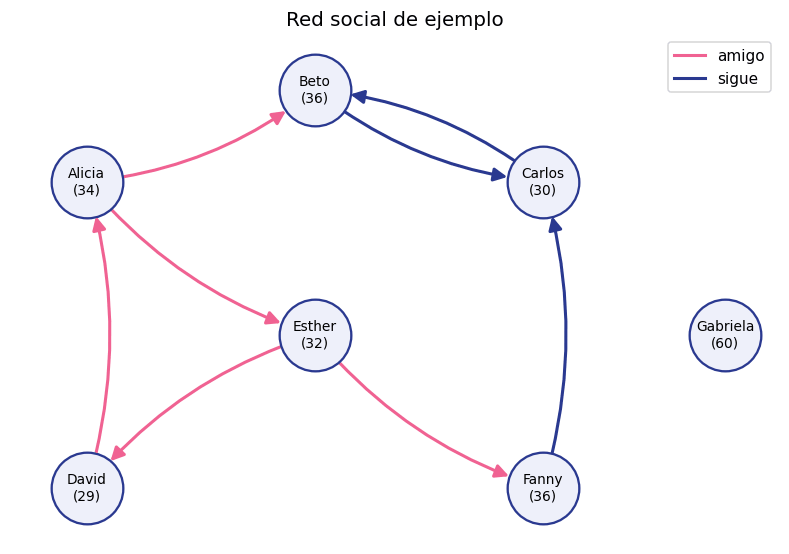

El **grado de entrada** de un vértice es cuántas aristas le llegan; en una red social sería su número de seguidores. Gabriela no aparece porque no tiene ninguna conexión.

In [ ]:
sp(r"""
g.inDegrees.orderBy(desc("inDegree")).show()
""")

### Subgrafos y patrones

`filterEdges` y `filterVertices` devuelven un nuevo GraphFrame. Al quitar un vértice también se van sus aristas.

In [ ]:
sp(r"""
solo_amigos = g.filterEdges("relacion = 'amigo'")
solo_amigos.edges.show()

mayores_30 = g.filterVertices("edad >= 30")
print("Aristas originales:", g.edges.count(), "| sin David:", mayores_30.edges.count())
""")

Con `find` buscamos **patrones** en el grafo. Este busca parejas que se siguen mutuamente: una arista de `x` a `y` y otra de regreso.

In [ ]:
sp(r"""
reciprocos = g.find("(x)-[e1]->(y); (y)-[e2]->(x)")

# Cada pareja aparece dos veces (x,y) y (y,x); nos quedamos con una
(reciprocos.filter("x.id < y.id")
    .select(col("x.nombre").alias("persona_1"), col("y.nombre").alias("persona_2"))
    .show())
""")

La cadena que recibe `find` es un pequeño lenguaje para describir patrones: `(x)` es un vértice, `-[e]->` es una arista con dirección y `;` significa "y además". Más ejemplos en la [guía de motif finding de GraphFrames](https://graphframes.io/04-user-guide/04-motif-finding.html).

## 2. Caso: correos de Enron

Enron fue una empresa energética estadounidense que quebró en 2001. Este archivo contiene 623 correos entre 143 empleados: cada renglón `i, j` es un correo del empleado `i` al `j`.

Asegúrate de haber copiado `email-enron-only.csv` a `/tmp/spark_local` (celda 3).

In [ ]:
sp(r"""
correos = (spark.read.csv(f"{DATA_DIR}/email-enron-only.csv", header=True, inferSchema=True)
           .withColumnRenamed("i", "src")
           .withColumnRenamed("j", "dst"))

# El archivo solo trae aristas: los vértices son todos los ids que aparecen en src o dst
empleados = (correos.select(col("src").alias("id"))
             .union(correos.select(col("dst").alias("id")))
             .distinct())

enron = GraphFrame(empleados, correos)
print("Empleados:", enron.vertices.count(), "| Correos:", enron.edges.count())
""")

### Grado: ¿quién tiene más conexiones?

`degrees` cuenta aristas de entrada y de salida.

In [ ]:
sp(r"""
enron.degrees.orderBy(desc("degree")).show(5)
""")

GraphFrames no es un mundo aparte: `edges` es un DataFrame y con `.rdd` volvemos a lo que vimos hoy. El mismo cálculo con `flatMap` y `reduceByKey`:

In [ ]:
sp(r"""
from operator import add

grados_rdd = (enron.edges.rdd
              .flatMap(lambda fila: [(fila.src, 1), (fila.dst, 1)])
              .reduceByKey(add))

grados_rdd.takeOrdered(5, key=lambda x: -x[1])
""")

### Componentes conexas: ¿hay grupos aislados?

Una componente conexa es un grupo de vértices que pueden alcanzarse entre sí (sin importar la dirección de las aristas). Toda la red de Enron está conectada. Veamos qué pasa si quitamos un solo correo.

In [ ]:
sp(r"""
componentes = enron.connectedComponents()
print("Componentes en la red completa:", componentes.select("component").distinct().count())

enron_sin_correo = enron.filterEdges("NOT (src = 130 AND dst = 98)")
componentes_2 = enron_sin_correo.connectedComponents()
print("Componentes sin el correo 130 -> 98:", componentes_2.select("component").distinct().count())

componentes_2.groupBy("component").count().show()
""")

El empleado 98 solo tenía ese correo, así que queda aislado.

### PageRank: ¿quién es más influyente?

PageRank da más importancia a un vértice cuando le llegan aristas de otros vértices importantes. Es el algoritmo con el que Google ordenaba páginas web.

In [ ]:
sp(r"""
resultado_pr = enron.pageRank(resetProbability=0.15, maxIter=10)

resultado_pr.vertices.orderBy(desc("pagerank")).show(5)
""")

Para dibujar el grafo lo traemos al driver con `toPandas()` y usamos NetworkX. Esto solo tiene sentido con grafos pequeños como este. El tamaño del nodo es su PageRank.

In [ ]:
sp(r"""
import networkx as nx
import matplotlib.pyplot as plt

pr = resultado_pr.vertices.toPandas()
aristas_pd = enron.edges.toPandas()

G = nx.DiGraph()
G.add_nodes_from(pr["id"])
G.add_edges_from(aristas_pd[["src", "dst"]].values)

tamanos = dict(zip(pr["id"], pr["pagerank"] * 150))

plt.figure(figsize=(10, 8))
pos = nx.spring_layout(G, seed=42)
nx.draw(G, pos,
        node_size=[tamanos[n] for n in G.nodes()],
        node_color="#F06292", edge_color="lightgray",
        with_labels=True, font_size=7, arrowsize=6)
plt.title("Red de correos de Enron (tamaño = PageRank)")
plt.show()
""")

## 3. ¿Y a escala? Red de Twitch

168 mil canales y 6.8 millones de conexiones entre ellos. Aquí ya no dibujamos nada: todo se queda en Spark.

Cada conexión es mutua y aparece una sola vez, así que usamos `degrees` en lugar de `inDegrees` u `outDegrees`.

Asegúrate de haber copiado `large_twitch_edges.csv` y `large_twitch_features.csv` a `/tmp/spark_local` (celda 3).

> Ojo: son 6.8 millones de conexiones en una sola máquina. Tarda varios minutos y puede quedarse sin memoria; si pasa, usa una muestra con `.sample(0.1)`.

In [ ]:
sp(r"""
canales = (spark.read.csv(f"{DATA_DIR}/large_twitch_features.csv", header=True, inferSchema=True)
           .withColumnRenamed("numeric_id", "id"))

conexiones = (spark.read.csv(f"{DATA_DIR}/large_twitch_edges.csv", header=True, inferSchema=True)
              .withColumnRenamed("numeric_id_1", "src")
              .withColumnRenamed("numeric_id_2", "dst"))

twitch = GraphFrame(canales, conexiones)
print("Canales:", twitch.vertices.count(), "| Conexiones:", twitch.edges.count())
""")

In [ ]:
sp(r"""
# Los 5 canales con más conexiones, junto con sus atributos
(twitch.degrees
    .join(twitch.vertices, "id")
    .select("id", "degree", "views", "language")
    .orderBy(desc("degree"))
    .show(5))
""")

## Ejercicios

**1.** En la red de Enron, usa `bfs` para encontrar el camino más corto del empleado `128` al `26`. ¿Quién es el intermediario?

**2.** En la red de Twitch, crea el subgrafo de canales en español (`language = 'ES'`). ¿Cuántos canales y conexiones tiene? ¿Cuáles son los 5 canales con más conexiones dentro de ese subgrafo?

In [ ]:
sp(r"""
# Escribe aquí tu código
""")

In [ ]:
sp(r"""
# Escribe aquí tu código
""")

In [ ]:
# Liberar los recursos: cierra Spark y el proceso local
sp.run("spark.stop()")
sp.stop()

---

### Notas y límites de esta versión

- **No es distribuido**: corre en una sola máquina (memoria estándar de Serverless, 16 GB; el motor pide 8 GB para el driver).
  Sirve para los ejemplos del curso, no para cargas grandes de producción.
- **El estado vive en el proceso local**: las variables existen dentro de `sp`, no en el notebook.
  Para traer algo al notebook, guárdalo en disco (`toPandas().to_csv("/tmp/spark_local/x.csv")`) y léelo con pandas.
- **`display()` de Databricks** no funciona con estos DataFrames; usa `.show()` como en Colab, o el truco del CSV.
- **Las gráficas de matplotlib** sí se ven: el motor las guarda y las muestra automáticamente debajo de la celda.
- **Si algo se traba o truena raro**: `sp.restart()` y vuelve a ejecutar las celdas desde donde haga falta.
- **Si Serverless se reinicia**, `/tmp` se borra: repite las celdas 1, 2 y 3.
- Esto es un *workaround*, no una función soportada por Databricks. En una cuenta de pago lo nativo sería
  un cluster clásico con access mode **Dedicated** y runtime **ML**.